# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.

## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.

In [1]:
import hashlib
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

SEED = 600  # only the bootstrap interval in the Model section depends on a draw
rng = np.random.default_rng(SEED)

DATA = Path("data")
FIG = Path("fig")
FIG.mkdir(exist_ok=True)

ZIP = DATA / "openpowerlifting-latest.zip"
ZIP_SHA256 = "26be6b73f4b16ba5f4f8fb568f258d2c5ab165f379aed21e2489af9d0022afe7"

sha = hashlib.sha256(ZIP.read_bytes()).hexdigest()
assert sha == ZIP_SHA256, f"data file does not match data/README.md: {sha}"
print("data file checked:", ZIP.name)

data file checked: openpowerlifting-latest.zip


## Question

After a made second squat attempt, how big a jump should a raw lifter take on the third? The quantity is the probability that the third squat attempt is made, for one lifter at one meet, as a function of the jump in kg. The decision it feeds is the jump, chosen to maximise the expected kilograms added: P(make | jump) × jump. The baseline rule is a fixed 5% jump.

The cell below draws the layer diagram and saves it as `fig/layers.png`.

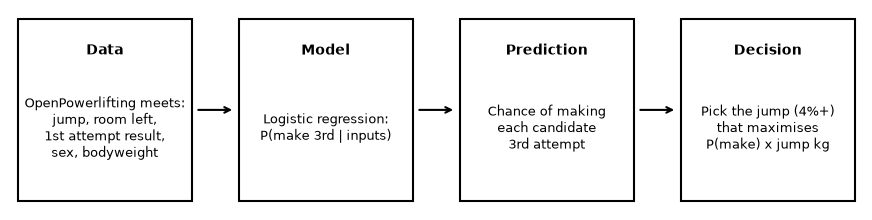

In [2]:
layers = [
    ("Data", "OpenPowerlifting meets:\njump, room left,\n1st attempt result,\nsex, bodyweight"),
    ("Model", "Logistic regression:\nP(make 3rd | inputs)"),
    ("Prediction", "Chance of making\neach candidate\n3rd attempt"),
    ("Decision", "Pick the jump (4%+)\nthat maximises\nP(make) x jump kg"),
]
fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (title, text) in enumerate(layers):
    x = i * 2.8
    ax.add_patch(plt.Rectangle((x, 0), 2.2, 2, fill=False, linewidth=1.5))
    ax.text(x + 1.1, 1.65, title, ha="center", va="center", fontweight="bold")
    ax.text(x + 1.1, 0.8, text, ha="center", va="center", fontsize=9)
    if i < len(layers) - 1:
        ax.annotate("", xy=(x + 2.75, 1), xytext=(x + 2.25, 1),
                    arrowprops=dict(arrowstyle="->", linewidth=1.5))
ax.set_xlim(-0.1, 4 * 2.8 - 0.5)
ax.set_ylim(-0.1, 2.1)
ax.axis("off")
fig.savefig(FIG / "layers.png", dpi=150, bbox_inches="tight")
plt.show()

## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

The file is the OpenPowerlifting bulk zip, read directly without unzipping. The filters are: full-power (SBD) meets, `Raw` equipment, all three squat attempts recorded, a made second attempt, a third attempt heavier than the second by at most 25%, sex `M` or `F`, and a recorded bodyweight. Failed attempts are stored as negative weights.

Room left: the lifter's best made raw squat at any meet on an earlier date, from the same archive. The lifter knows it before choosing the third attempt. `second_vs_best` is the second attempt divided by that earlier best: above 1 means the second attempt was already past the lifter's previous best, so there is little room left.

The first run reads the 800 MB CSV inside the zip, which takes a minute or two. It saves the filtered rows to `data/squat3_room.pkl` (ignored by git) so later runs are fast.

In [3]:
CACHE = DATA / "squat3_room.pkl"

if CACHE.exists():
    d = pd.read_pickle(CACHE)
else:
    cols = ["Name", "Sex", "Event", "Equipment", "BodyweightKg", "Date",
            "Squat1Kg", "Squat2Kg", "Squat3Kg", "Best3SquatKg"]
    with zipfile.ZipFile(ZIP) as z:
        csv_name = next(n for n in z.namelist() if n.endswith(".csv"))
        with z.open(csv_name) as f:
            opl = pd.read_csv(f, usecols=cols, low_memory=False, parse_dates=["Date"])

    # each lifter's best made raw squat at any EARLIER meet date (never the same meet)
    made_squats = opl[(opl.Equipment == "Raw") & (opl.Best3SquatKg > 0)]
    day_best = (made_squats.groupby(["Name", "Date"]).Best3SquatKg.max()
                .reset_index().sort_values(["Name", "Date"]))
    day_best["prior_best"] = (day_best.groupby("Name").Best3SquatKg
                              .transform(lambda s: s.cummax().shift()))

    attempts = ["Squat1Kg", "Squat2Kg", "Squat3Kg"]
    d = opl[(opl.Event == "SBD") & (opl.Equipment == "Raw")
            & opl[attempts].notna().all(axis=1) & (opl.Squat2Kg > 0)].copy()
    del opl

    d["jump_kg"] = d.Squat3Kg.abs() - d.Squat2Kg            # planned gain if the 3rd is made
    d["jump_pct"] = d.jump_kg / d.Squat2Kg
    d = d[(d.jump_pct > 0) & (d.jump_pct <= 0.25)]
    d = d[d.Sex.isin(["M", "F"]) & d.BodyweightKg.notna()].copy()
    d = d.merge(day_best[["Name", "Date", "prior_best"]], on=["Name", "Date"], how="left")

    d["made3"] = (d.Squat3Kg > 0).astype(int)                # the outcome
    d["made1"] = (d.Squat1Kg > 0).astype(int)
    d["jump12_pct"] = (d.Squat2Kg - d.Squat1Kg.abs()) / d.Squat1Kg.abs()
    d["male"] = (d.Sex == "M").astype(int)
    d["second_vs_best"] = d.Squat2Kg / d.prior_best          # room left
    d.to_pickle(CACHE)

print(f"{len(d):,} third attempts, {d.Name.nunique():,} lifter names, "
      f"{d.Date.min().date()} to {d.Date.max().date()}; "
      f"{d.prior_best.notna().sum():,} have an earlier meet")

757,813 third attempts, 302,485 lifter names, 1965-09-04 to 2026-10-18; 484,979 have an earlier meet


One plot of the raw data before any model: how big lifters jump, and how often each jump size is made.

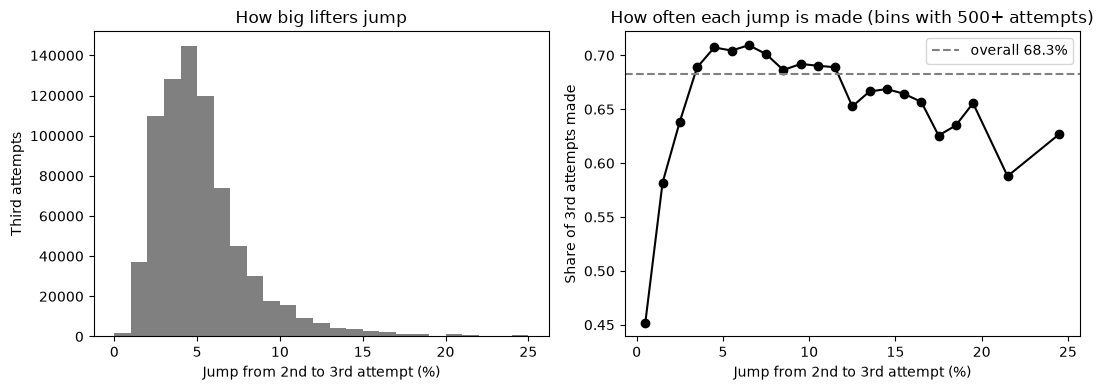

In [4]:
bins = np.arange(0, 0.26, 0.01)
d["jump_bin"] = pd.cut(d.jump_pct, bins)
by_bin = d.groupby("jump_bin", observed=True).agg(n=("made3", "size"), make_rate=("made3", "mean"))
by_bin = by_bin[by_bin.n >= 500]
mid = [b.mid * 100 for b in by_bin.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(d.jump_pct * 100, bins=bins * 100, color="grey")
ax1.set_xlabel("Jump from 2nd to 3rd attempt (%)")
ax1.set_ylabel("Third attempts")
ax1.set_title("How big lifters jump")

ax2.plot(mid, by_bin.make_rate, marker="o", color="black")
ax2.axhline(d.made3.mean(), linestyle="--", color="grey", label=f"overall {d.made3.mean():.1%}")
ax2.set_xlabel("Jump from 2nd to 3rd attempt (%)")
ax2.set_ylabel("Share of 3rd attempts made")
ax2.set_title("How often each jump is made (bins with 500+ attempts)")
ax2.legend()
fig.tight_layout()
fig.savefig(FIG / "raw_jump.png", dpi=150, bbox_inches="tight")
plt.show()

One table of summary statistics, by sex and overall.

In [5]:
def summarise(g):
    return pd.Series({
        "third attempts": len(g),
        "made (%)": 100 * g.made3.mean(),
        "median jump (kg)": g.jump_kg.median(),
        "median jump (%)": 100 * g.jump_pct.median(),
        "median 2nd attempt (kg)": g.Squat2Kg.median(),
        "median bodyweight (kg)": g.BodyweightKg.median(),
        "1st attempt made (%)": 100 * g.made1.mean(),
        "has earlier meet (%)": 100 * g.prior_best.notna().mean(),
        "median 2nd / earlier best": g.second_vs_best.median(),
    })

summary = d.groupby("Sex").apply(summarise, include_groups=False)
summary.loc["All"] = summarise(d)
summary.round(2)

,third attempts,made (%),median jump (kg),median jump (%),median 2nd attempt (kg),median bodyweight (kg),1st attempt made (%),has earlier meet (%),median 2nd / earlier best
Sex,,,,,,,,,
F,253175.0,67.69,5.0,5.08,110.0,67.3,90.13,65.76,1.0
M,504638.0,68.61,7.5,4.44,190.0,87.9,89.98,63.11,1.0
All,757813.0,68.30,7.5,4.65,165.0,81.3,90.03,64.00,1.0


### Room left check

Small jumps fail more often than medium ones in the raw plot. That does not mean a small jump is harder: a lifter who barely made the second attempt takes a small jump, so the small-jump rows are mostly tired lifters (issue #1). The check: among lifters with the same room left, a bigger jump should be harder to make. If small jumps still fail more often inside a group, room left is not a good enough stand-in for how the second attempt felt.

Rows here: lifters with an earlier meet whose second attempt was 80% to 120% of the earlier best. Outside that range the earlier best looks like a comeback or two lifters with the same name.

In [6]:
has_room = d[d.second_vs_best.between(0.8, 1.2)].copy()
has_room["room_group"] = pd.cut(has_room.second_vs_best, [0.8, 0.95, 1.0, 1.05, 1.2],
                                labels=["2nd under 95% of best", "95-100%", "100-105%", "2nd over 105% of best"])
has_room["jump_group"] = pd.cut(has_room.jump_pct, [0, .02, .04, .06, .08, .10, .25],
                                labels=["0-2%", "2-4%", "4-6%", "6-8%", "8-10%", "10%+"])

check = has_room.pivot_table(index="room_group", columns="jump_group", values="made3",
                             aggfunc="mean", observed=True)
print(f"{len(has_room):,} attempts. Share of 3rd attempts made:")
check.round(3)

456,553 attempts. Share of 3rd attempts made:


jump_group,0-2%,2-4%,4-6%,6-8%,8-10%,10%+
room_group,,,,,,
2nd under 95% of best,0.613,0.725,0.755,0.729,0.710,0.671
95-100%,0.584,0.677,0.707,0.692,0.651,0.626
100-105%,0.566,0.660,0.698,0.689,0.652,0.593
2nd over 105% of best,0.524,0.620,0.658,0.652,0.629,0.596


In [7]:
# same table, only lifters who made their opener
has_room[has_room.made1 == 1].pivot_table(index="room_group", columns="jump_group", values="made3",
                                          aggfunc="mean", observed=True).round(3)

jump_group,0-2%,2-4%,4-6%,6-8%,8-10%,10%+
room_group,,,,,,
2nd under 95% of best,0.623,0.735,0.772,0.750,0.735,0.700
95-100%,0.588,0.682,0.716,0.703,0.675,0.654
100-105%,0.569,0.664,0.704,0.693,0.662,0.607
2nd over 105% of best,0.526,0.624,0.664,0.658,0.637,0.614


What the check shows. Reading down any column, less room left means a lower make rate, as expected. From about 5% up, a bigger jump is harder to make within every room group, as expected. Below 4% the check fails: within every group, 0–2% jumps are made least often, also among lifters who made their opener. Room left is not a good enough stand-in for a hard second attempt in that range.

So the rule is limited to jumps of 4% or more for now, and the model is fitted and scored only on those jumps. It does not advise on smaller jumps. Before the final, try a better stand-in for how hard the second attempt was and rerun this table.

In [8]:
rows = has_room[has_room.jump_pct >= 0.04].copy()
print(f"{len(rows):,} attempts with room left and a jump of 4% or more")

258,222 attempts with room left and a jump of 4% or more


## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.

The decision is about meets that have not happened yet, so the held-out set is a later time: every meet from 1 January 2025 on. Room left uses only earlier meets, so a held-out row never sees its own meet.

In [9]:
CUTOFF = "2025-01-01"
train = rows[rows.Date < CUTOFF]
test = rows[rows.Date >= CUTOFF]

print(f"train: {len(train):,} attempts, {train.Date.min().date()} to {train.Date.max().date()}, made {train.made3.mean():.1%}")
print(f"test:  {len(test):,} attempts, {test.Date.min().date()} to {test.Date.max().date()}, made {test.made3.mean():.1%}")

train: 192,789 attempts, 1973-09-08 to 2024-12-29, made 69.2%
test:  65,433 attempts, 2025-01-01 to 2026-10-18, made 70.3%


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.

The prediction baseline gives every attempt the training make rate. The score is in kilograms. For each held-out attempt the expected gain is P(make) × jump, and the realised gain is the jump if the attempt was made and 0 if it was missed. The score is how far the expected gain is from the realised gain, as a root mean square and a mean absolute error, in kg. The Brier score, the mean squared error of the probability, is shown alongside. The fixed 5% jump is the baseline for the decision rule, scored in the Decision section.

In [10]:
def kg_scores(p, df):
    jump = df.jump_kg.to_numpy()
    made = df.made3.to_numpy()
    expected = p * jump          # expected kg added
    realised = made * jump       # kg actually added
    return pd.Series({
        "RMSE (kg)": np.sqrt(np.mean((expected - realised) ** 2)),
        "MAE (kg)": np.mean(np.abs(expected - realised)),
        "mean expected gain (kg)": expected.mean(),
        "mean realised gain (kg)": realised.mean(),
        "Brier": np.mean((p - made) ** 2),
    })

p_base = np.full(len(test), train.made3.mean())
scores = pd.DataFrame({"baseline: training make rate": kg_scores(p_base, test)})
scores.round(4)

,baseline: training make rate
RMSE (kg),4.8740
MAE (kg),4.1428
mean expected gain (kg),6.7501
mean realised gain (kg),6.7886
Brier,0.2089


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.

Logistic regression for the chance of making the third attempt, fitted on jumps of 4% or more:

$$\log\frac{p}{1-p} = \beta_0 + \beta_1\,\text{jump} + \beta_2\,\text{room} + \beta_3\,\text{made1} + \beta_4\,\text{jump12} + \beta_5\,\text{male} + \beta_6\,\text{bodyweight}$$

- `jump`: the 2nd-to-3rd jump as a fraction of the 2nd attempt. $\beta_1$ should be negative: with the rest fixed, a bigger jump is harder.
- `room`: `second_vs_best`, the 2nd attempt divided by the lifter's best from earlier meets. $\beta_2$ should be negative: a 2nd attempt already past the old best leaves less in the tank.
- `made1`: 1 if the first attempt was made. A missed opener is a sign of a hard day.
- `jump12`: the 1st-to-2nd jump as a fraction of the 1st attempt.
- `male`, `bodyweight`: who is lifting.
- Each $\beta$ is a change in the log-odds of making the attempt for a one-unit change in that input, with the others held fixed.

The assumption I trust least: that room left and the opener result capture how the second attempt felt. The check above shows they do not below 4%, so they may not fully do it above 4% either, and $\beta_1$ can still carry some of that. The model also assumes attempts are independent, but the same lifter appears at many meets.

`C=1e6` makes the fit effectively unpenalised, a plain maximum-likelihood logistic regression. `tol=1e-8` makes the optimiser run until the coefficients stop moving: at the default tolerance it stops early and the jump coefficient comes out wrong (see `decisions.md`).

In [11]:
features = ["jump_pct", "second_vs_best", "made1", "jump12_pct", "male", "BodyweightKg"]

model = LogisticRegression(C=1e6, tol=1e-8, max_iter=5000)
model.fit(train[features], train.made3)

coefs = pd.Series(model.coef_[0], index=features)
coefs["intercept"] = model.intercept_[0]
coefs.round(3)

jump_pct         -3.186
second_vs_best   -2.264
made1             0.455
jump12_pct       -0.024
male             -0.022
BodyweightKg      0.008
intercept         2.240
dtype: float64

In [12]:
p_model = model.predict_proba(test[features])[:, 1]
scores["model: logistic regression"] = kg_scores(p_model, test)
scores.round(4)

,baseline: training make rate,model: logistic regression
RMSE (kg),4.8740,4.8272
MAE (kg),4.1428,4.0388
mean expected gain (kg),6.7501,6.8372
mean realised gain (kg),6.7886,6.7886
Brier,0.2089,0.2056


Uncertainty of the prediction. For a typical lifter (male, 93 kg bodyweight, opener made, 5% jump from 1st to 2nd, 2nd attempt equal to the earlier best), the predicted chance of making the third attempt at three jump sizes, with a 95% interval from refitting on 20 bootstrap resamples of the training rows (seed 600). The prediction for a single attempt is a probability: the attempt is made or missed, so even a well-estimated 70% chance misses three times in ten.

In [13]:
typical = pd.DataFrame({"jump_pct": [0.04, 0.06, 0.08]})
typical["second_vs_best"] = 1.0
typical["made1"] = 1
typical["jump12_pct"] = 0.05
typical["male"] = 1
typical["BodyweightKg"] = 93.0
typical = typical[features]

boot = []
for _ in range(20):
    idx = rng.integers(0, len(train), len(train))
    sample = train.iloc[idx]
    m = LogisticRegression(C=1e6, tol=1e-8, max_iter=5000).fit(sample[features], sample.made3)
    boot.append(m.predict_proba(typical)[:, 1])
boot = np.array(boot)

pd.DataFrame({
    "jump (%)": typical.jump_pct * 100,
    "P(make)": model.predict_proba(typical)[:, 1],
    "2.5%": np.percentile(boot, 2.5, axis=0),
    "97.5%": np.percentile(boot, 97.5, axis=0),
}).round(3)

,jump (%),P(make),2.5%,97.5%
0,4.0,0.733,0.729,0.735
1,6.0,0.720,0.716,0.722
2,8.0,0.707,0.703,0.711


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.

## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.

## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.

## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.